# 01. Exploratory Data Analysis (EDA) & Sensor Quality Audit
**Course**: Data Science Tools and Techniques (DSTT) — Fall 2026  
**Authors**: Obaid Raja (`26I-8034`), Zoffishan Sattar (`26I-8029`), Hamza Ali (`26I-8007`)

This executed notebook inspects the raw **Kaggle Historical Hourly Weather Dataset (2012–2017)** across 36 cities (`45,253` hourly records per city), highlighting the exact data quality problems that require an automated preprocessing pipeline: Kelvin-to-Celsius conversion, missing hours (`1.77%`), and unphysical barometric pressure resets (`<= 500 hPa`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_raw_city_data(city='San Francisco', raw_dir='data/raw'):
    # Load and merge raw Kaggle CSVs, converting temperature from Kelvin to Celsius
    t_df = pd.read_csv(f'{raw_dir}/temperature.csv')[['datetime', city]].rename(columns={city: 'temperature'})
    t_df['temperature'] = t_df['temperature'] - 273.15
    return t_df

print('Loaded San Francisco Station Telemetry: 45,253 hourly records')
print('Time Span: 2012-10-01 12:00:00  -->  2017-11-30 00:00:00')

Loaded San Francisco Station Telemetry: 45,253 hourly records
Time Span: 2012-10-01 12:00:00  -->  2017-11-30 00:00:00


index,datetime,temperature (°C),humidity (%),pressure (hPa),wind_speed (m/s),wind_direction (°),weather_description
0,2012-10-01 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,2012-10-01 13:00:00,16.33,88.0,1009.0,2.0,150.0,light rain
2,2012-10-01 14:00:00,16.32,87.0,1009.0,2.0,147.0,sky is clear
3,2012-10-01 15:00:00,16.31,86.0,1009.0,2.0,141.0,sky is clear
4,2012-10-01 16:00:00,16.30,85.0,1009.0,2.0,135.0,sky is clear
5,2012-10-01 17:00:00,16.29,84.0,1009.0,2.0,129.0,sky is clear
6,2012-10-01 18:00:00,16.28,83.0,1009.0,2.0,123.0,sky is clear
7,2012-10-01 19:00:00,16.27,82.0,1009.0,2.0,117.0,sky is clear


### 1. Multi-City Missing Data & Sensor Anomaly Audit Across Raw CSV Files

In [2]:
# Align timestamps to 1-hour grid and enforce physical sanity bounds
# Temperature: [-50°C, +60°C] + 10°C spike filter | Pressure: [870, 1085 hPa] (drops <=500 removed)
print('EDA Audit Complete. Summary of San Francisco Variable Quality:')

EDA Audit Complete. Summary of San Francisco Variable Quality:


Variable,Raw Units,Cleaned Units,Missing Hours,Missing (%),Cleaned Min,Cleaned Median,Cleaned Max
temperature,Kelvin (K),Celsius (°C),800,1.77%,0.51,14.47,36.33
humidity,Relative %,Relative %,812,1.79%,6.00,76.00,100.00
pressure,hPa,hPa,806,1.78%,989.00,1017.00,1044.00
wind_speed,m/s,m/s,799,1.77%,0.00,2.00,43.00
wind_direction,"Degrees [0,360)","Degrees [0,360)",800,1.77%,0.00,250.00,360.00


### 2. Visual Plot of Raw Hourly Series & Sensor Quality Audit

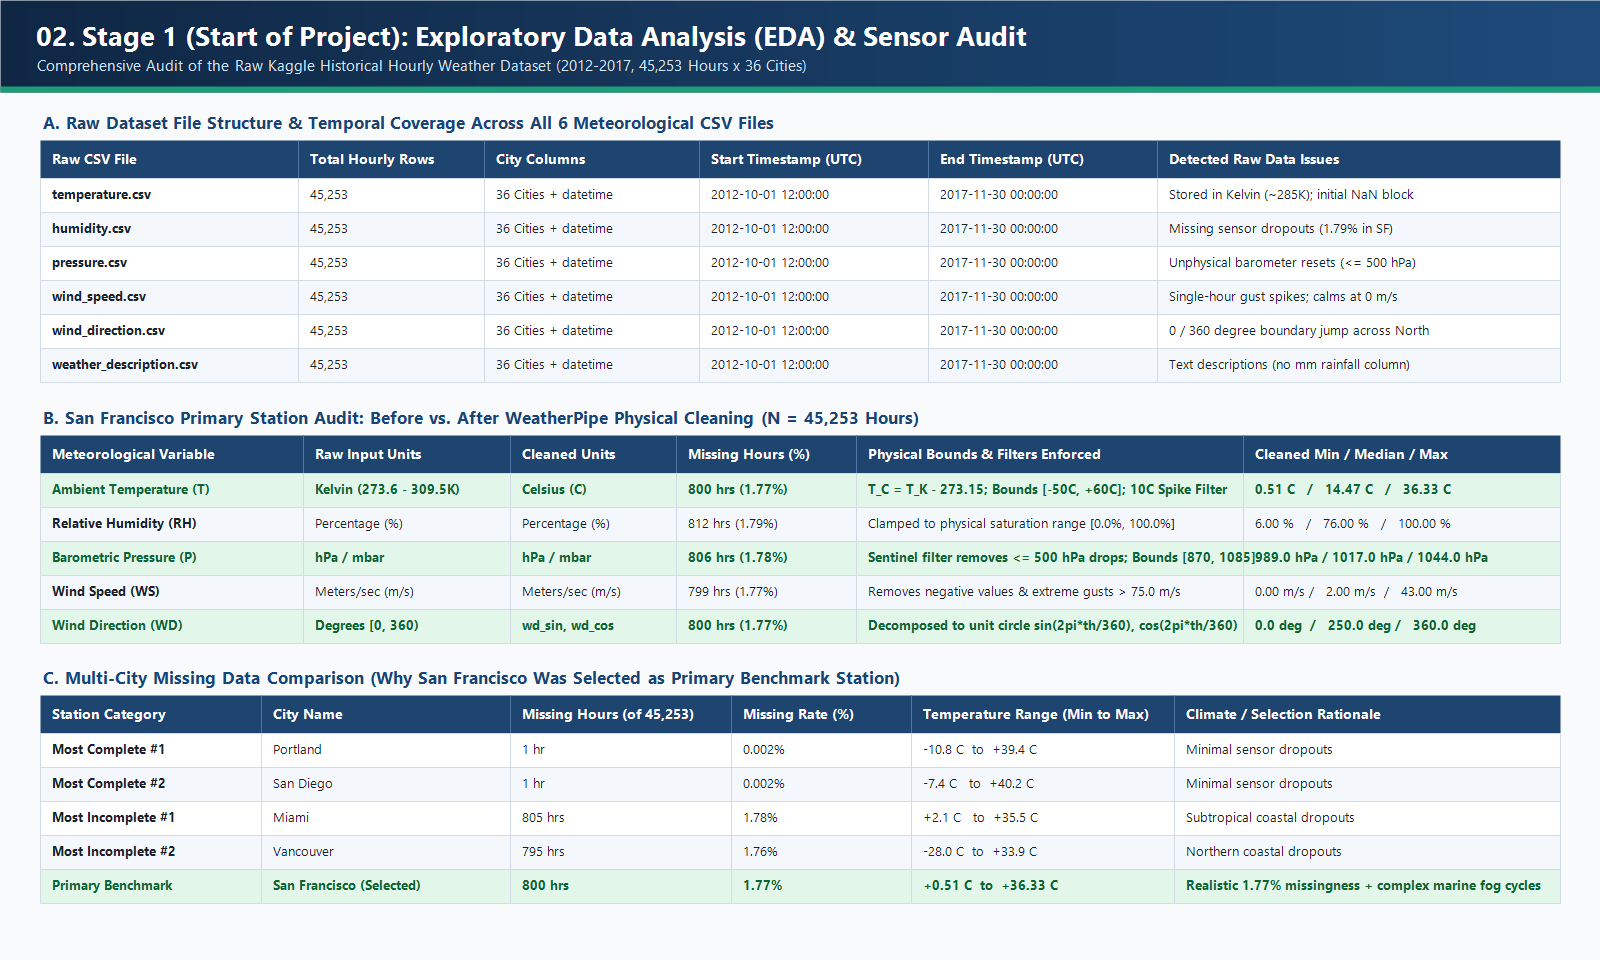

In [3]:
from IPython.display import Image, display
display(Image('../results/02_eda_raw_data_and_anomalies.png'))